# Neural Receiver for OFDM SIMO Systems

In this notebook, you will learn how to train a neural receiver that implements OFDM detection.
The considered setup is shown in the figure below.
As one can see, the neural receiver substitutes channel estimation, equalization, and demapping.
It takes as input the post-DFT (discrete Fourier transform) received samples, which form the received resource grid, and computes log-likelihood ratios (LLRs) on the transmitted coded bits.
These LLRs are then fed to the outer decoder to reconstruct the transmitted information bits.

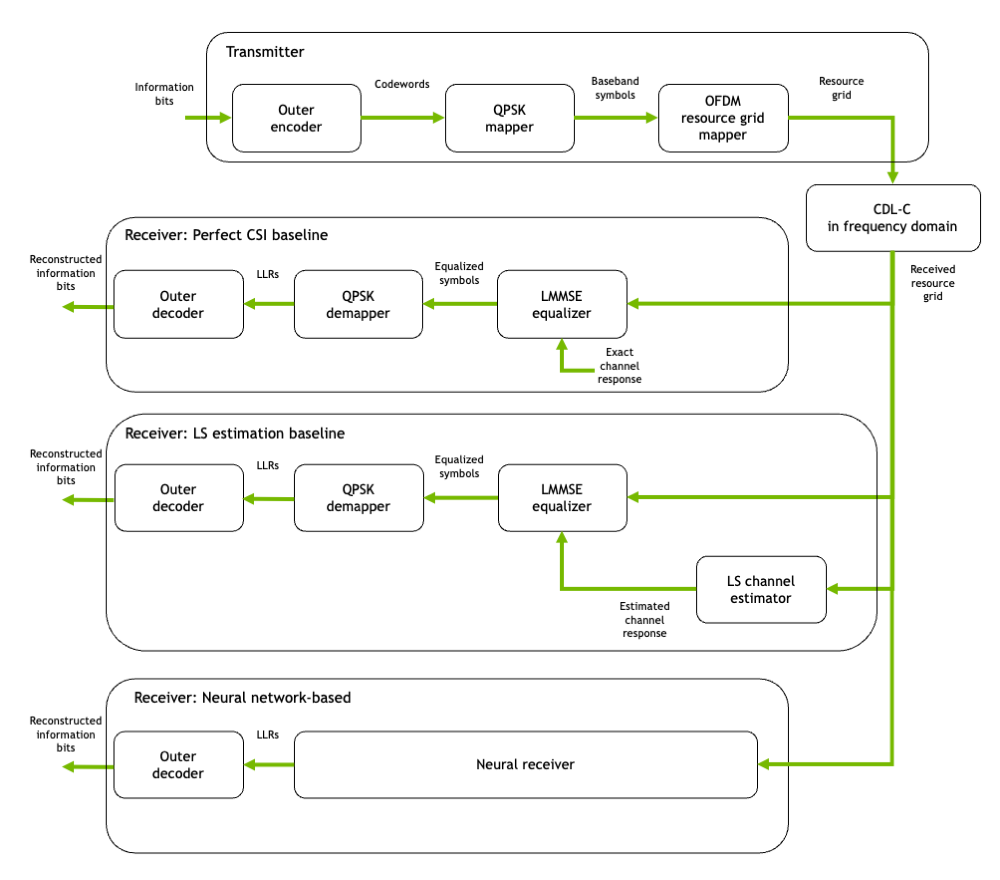

Two baselines are considered for benchmarking, which are shown in the figure above.
Both baselines use linear minimum mean square error (LMMSE) equalization and demapping assuming additive white Gaussian noise (AWGN).
They differ by how channel estimation is performed:

- **Pefect CSI**: Perfect channel state information (CSI) knowledge is assumed.
- **LS estimation**: Uses the transmitted pilots to perform least squares (LS) estimation of the channel with nearest-neighbor interpolation.

All the considered end-to-end systems use an LDPC outer code from the 5G NR specification, QPSK modulation, and a 3GPP CDL channel model simulated in the frequency domain.

* [Configuration and Imports](#Configuration-and-Imports)
* [Simulation Parameters](#Simulation-Parameters)
* [Neural Receiver](#Neural-Receiver)
* [End-to-end System](#End-to-end-System)
* [End-to-end System as a Sionna Block](#End-to-end-System-as-a-Sionna-Block)
* [Evaluation of the Baselines](#Evaluation-of-the-Baselines)
* [Training the Neural Receiver](#Training-the-Neural-Receiver)
* [Evaluation of the Neural Receiver](#Evaluation-of-the-Neural-Receiver)
* [Pre-computed Results](#Pre-computed-Results)
* [References](#References)

## Configuration and Imports <a class="anchor" id="Configuration-and-Imports"></a>

In [1]:
# ==============================================================================
# SINGLE-SOURCE CONFIGURATION & ENVIRONMENT SETUP (nrx-bounded)
# ==============================================================================
import sys
from pathlib import Path

# Tự động phát hiện thư mục gốc của repository nrx-bounded
repo_root = Path.cwd().resolve()
while repo_root.name != "nrx-bounded" and repo_root.parent != repo_root:
    repo_root = repo_root.parent
if str(repo_root) not in sys.path and (repo_root / "config" / "config.yaml").exists():
    sys.path.insert(0, str(repo_root))

try:
    from src.config import load_config
    from src.utils import set_all_seeds
    cfg = load_config()
    set_all_seeds(cfg.get("seed", 42))
    print("✓ Đã nạp thành công cấu hình đơn nguồn từ config/config.yaml")
except Exception as e:
    cfg = {}
    print(f"⚠️ Chạy chế độ độc lập (Standalone Mode): {e}")

import os
import sys
import shutil
import re
# 1. Mở cửa cho GPU số 0 (T4 của Colab)
os.environ["CUDA_VISIBLE_DEVICES"] = "0"

try:
    import sionna.phy
except ImportError as e:
    if 'google.colab' in sys.modules:
        print("Đang cài đặt Sionna...")
        os.system("pip install --upgrade sionna thop -q")
        print("Hệ thống tự động Restart Runtime. Vui lòng CHẠY LẠI CELL NÀY sau vài giây...")
        os.kill(os.getpid(), 5)
    else:
        raise e

# 2. Thiết lập Seed
sionna.phy.config.seed = 42

# 3. ĐỂ SIONNA TỰ NHẬN DIỆN VÀ LẤY THÔNG TIN THIẾT BỊ
device = sionna.phy.config.device

# Kiểm tra xem Sionna đã túm được GPU chưa
if "cuda" in str(device).lower():
    print(f"✅ Đã kích hoạt thành công GPU T4 trên Google Colab! (Đang chạy trên: {device})")
else:
    print(f"⚠️ CẢNH BÁO: GPU chưa được bật ở menu Runtime. Hệ thống đang chạy bằng {device}.")

✅ Đã kích hoạt thành công GPU T4 trên Google Colab! (Đang chạy trên: cuda:0)


In [2]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import math
from fractions import Fraction

import torch
import torch.nn as nn
import torch.nn.functional as F

from google.colab import files

from sionna.phy import Block
from sionna.phy.channel.tr38901 import Antenna, AntennaArray, CDL
from sionna.phy.channel import OFDMChannel
from sionna.phy.mimo import StreamManagement
from sionna.phy.ofdm import ResourceGrid, ResourceGridMapper, LSChannelEstimator, \
                            LMMSEEqualizer, RemoveNulledSubcarriers, ResourceGridDemapper
from sionna.phy.utils import ebnodb2no, insert_dims, expand_to_rank, sim_ber
from sionna.phy.fec.ldpc import LDPC5GEncoder, LDPC5GDecoder
from sionna.phy.mapping import Mapper, Demapper, BinarySource

## Simulation Parameters <a class="anchor" id="Simulation-Parameters"></a>

In [3]:
############################################
## Channel configuration
carrier_frequency = cfg.get("phy", {}).get("carrier_frequency", 3.5e9) # Hz
delay_spread = cfg.get("channel", {}).get("delay_spread", 100e-9) # s
min_speed = cfg.get("channel", {}).get("min_speed", cfg.get("channel", {}).get("speed_min", 0.0)) # Min speed [m/s]
max_speed = cfg.get("channel", {}).get("max_speed", cfg.get("channel", {}).get("speed_max", 97.2)) # Max speed [m/s] (350 km/h)
cdl_model = cfg.get("channel", {}).get("cdl_model", "C") # Base CDL model (CDL-B, CDL-C, CDL-D used in training)

############################################
## OFDM waveform configuration
subcarrier_spacing = cfg.get("phy", {}).get("subcarrier_spacing", 30e3) # Hz
fft_size = cfg.get("phy", {}).get("fft_size", 128) # Number of subcarriers forming resource grid
num_ofdm_symbols = cfg.get("phy", {}).get("num_ofdm_symbols", 14) # Number of OFDM symbols
dc_null = cfg.get("phy", {}).get("dc_null", True) # Null DC subcarrier
num_guard_carriers = cfg.get("phy", {}).get("num_guard_carriers", [5, 6]) # Guard carriers on each side
pilot_pattern = cfg.get("phy", {}).get("pilot_pattern", "kronecker") # Pilot pattern
pilot_ofdm_symbol_indices = cfg.get("phy", {}).get("pilot_ofdm_symbol_indices", [2, 11]) # Symbols carrying pilots
cyclic_prefix_length = cfg.get("phy", {}).get("cyclic_prefix_length", 0)

############################################
## Modulation and coding configuration
num_bits_per_symbol = cfg.get("phy", {}).get("modulation", {}).get("num_bits_per_symbol", 6) # 64-QAM (6 bits/symbol)
coderate = cfg.get("phy", {}).get("coderate", 0.9) # Coderate for LDPC code

############################################
## Neural receiver configuration
num_conv_channels = cfg.get("models", {}).get("proposed_axial", {}).get("d_model", 128)
d_model = num_conv_channels
num_layers = cfg.get("models", {}).get("proposed_axial", {}).get("num_layers", 6)
nhead = cfg.get("models", {}).get("proposed_axial", {}).get("num_heads", 4)
in_channels = cfg.get("models", {}).get("proposed_axial", {}).get("in_channels", 11)
cnn_num_blocks = cfg.get("models", {}).get("baseline_cnn", {}).get("num_blocks", 4)

# SNR range for evaluation and training [dB]
ebno_db_min = cfg.get("training", {}).get("ebno_db_min", 0)
ebno_db_max = cfg.get("training", {}).get("ebno_db_max", 20)

############################################
## Training configuration
num_training_iterations = cfg.get("training", {}).get("iterations", 430000)
training_batch_size = cfg.get("training", {}).get("batch_size", 16)
model_weights_path = f"neural_receiver_results_64QAM_0_9_{int(min_speed)}_{int(max_speed)}ms"

############################################
## Evaluation configuration
results_filename = f"neural_receiver_results_64QAM_0_9_{int(min_speed)}_{int(max_speed)}ms_compare"


The `StreamManagement` class is used to configure the receiver-transmitter association and the number of streams per transmitter.
A SIMO system is considered, with a single transmitter equipped with a single non-polarized antenna.
Therefore, there is only a single stream, and the receiver-transmitter association matrix is $[1]$.
The receiver is equipped with an antenna array.

In [4]:
stream_manager = StreamManagement(np.array([[1]]), # Receiver-transmitter association matrix
                                  1)               # One stream per transmitter

The `ResourceGrid` class is used to configure the OFDM resource grid. It is initialized with the parameters defined above.

In [5]:
resource_grid = ResourceGrid(num_ofdm_symbols = num_ofdm_symbols,
                             fft_size = fft_size,
                             subcarrier_spacing = subcarrier_spacing,
                             num_tx = 1,
                             num_streams_per_tx = 1,
                             cyclic_prefix_length = cyclic_prefix_length,
                             dc_null = dc_null,
                             pilot_pattern = pilot_pattern,
                             pilot_ofdm_symbol_indices = pilot_ofdm_symbol_indices,
                             num_guard_carriers = num_guard_carriers)

Outer coding is performed such that all the databits carried by the resource grid with size `fft_size`x`num_ofdm_symbols` form a single codeword.

In [6]:
# Codeword length. It is calculated from the total number of databits carried by the resource grid, and the number of bits transmitted per resource element
n = int(resource_grid.num_data_symbols*num_bits_per_symbol)
# Number of information bits per codeword
k = int(n*coderate)

The SIMO link is setup by considering an uplink transmission with one user terminal (UT) equipped with a single non-polarized antenna, and a base station (BS) equipped with an antenna array.
One can try other configurations for the BS antenna array.

In [7]:
ut_antenna = Antenna(polarization="single",
                     polarization_type="V",
                     antenna_pattern="38.901",
                     carrier_frequency=carrier_frequency)

bs_array = AntennaArray(num_rows=1,
                        num_cols=1,
                        polarization="dual",
                        polarization_type="VH",
                        antenna_pattern="38.901",
                        carrier_frequency=carrier_frequency)

## Neural Receiver ##

The next cell defines the PyTorch modules that implement the neural receiver.
As in [1] and [2], a neural receiver using residual convolutional layers is implemented. Convolutional layers are leveraged to efficienly process the 2D resource grid, that is fed as an input to the neural receiver.
Residual (skip) connections are used to avoid gradient vanishing [3].

For convenience, a PyTorch module that implements a *residual block* is first defined. The module that implements the neural receiver is built by stacking such blocks. The following figure shows the architecture of the neural receiver.

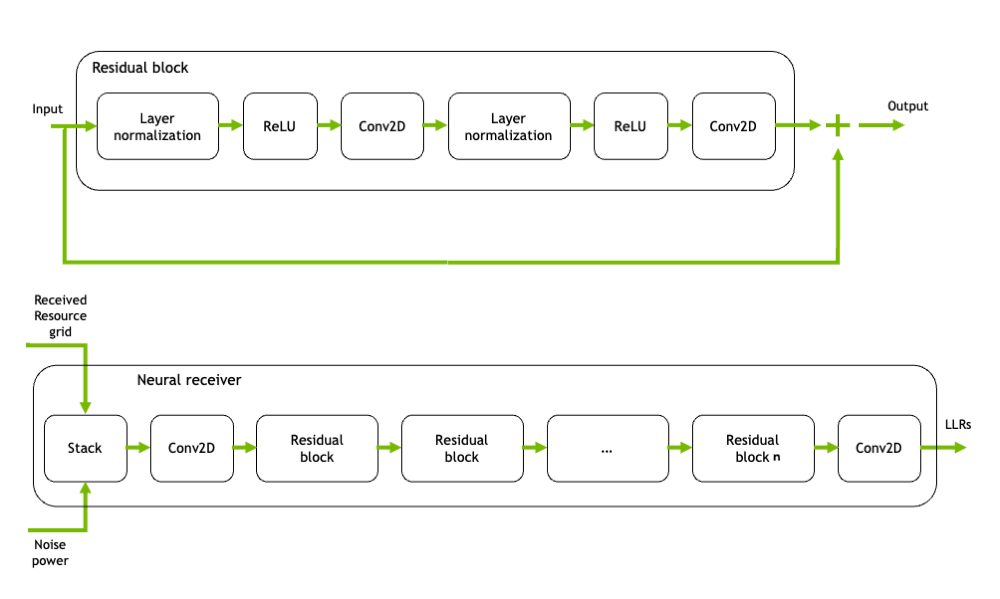

In [8]:
class ResidualBlock(nn.Module):
    """
    Convolutional residual block with two convolutional layers, ReLU activation,
    layer normalization, and a skip connection.

    The number of convolutional channels of the input must match num_conv_channels
    for the skip connection to work.

    Input shape: [batch_size, num_conv_channels, num_ofdm_symbols, num_subcarriers]
    Output shape: [batch_size, num_conv_channels, num_ofdm_symbols, num_subcarriers]
    """

    def __init__(self, num_conv_channels: int):
        super().__init__()
        # Layer normalization over the last three dimensions (C, H, W)
        self._layer_norm_1 = nn.LayerNorm([num_conv_channels, num_ofdm_symbols, fft_size])
        self._conv_1 = nn.Conv2d(
            in_channels=num_conv_channels,
            out_channels=num_conv_channels,
            kernel_size=3,
            padding=1,  # 'same' padding
        )
        self._layer_norm_2 = nn.LayerNorm([num_conv_channels, num_ofdm_symbols, fft_size])
        self._conv_2 = nn.Conv2d(
            in_channels=num_conv_channels,
            out_channels=num_conv_channels,
            kernel_size=3,
            padding=1,
        )

    def forward(self, inputs: torch.Tensor) -> torch.Tensor:
        z = self._layer_norm_1(inputs)
        z = F.relu(z)
        z = self._conv_1(z)
        z = self._layer_norm_2(z)
        z = F.relu(z)
        z = self._conv_2(z)
        # Skip connection
        z = z + inputs
        return z


class NeuralReceiver_CNN(nn.Module):
    """
    Residual convolutional neural receiver.

    This neural receiver is fed with the post-DFT received samples, forming a
    resource grid of size num_ofdm_symbols x fft_size, and computes LLRs on
    the transmitted coded bits.

    Input
    -----
    y : [batch_size, num_rx_antenna, num_ofdm_symbols, num_subcarriers], complex
        Received post-DFT samples.
    no : [batch_size], float
        Noise variance.

    Output
    ------
    llr : [batch_size, num_ofdm_symbols, num_subcarriers, num_bits_per_symbol], float
        LLRs on the transmitted bits.
    """

    def __init__(self, num_conv_channels: int, num_bits_per_symbol: int):
        super().__init__()
        self._num_bits_per_symbol = num_bits_per_symbol

        # Input convolution: 2*num_rx_antenna + 1 input channels (real, imag, noise)
        # For dual polarization: 2*2 + 1 = 5 input channels
        num_input_channels = 2 * 2 + 1  # 2 antennas, real+imag, plus noise
        self._input_conv = nn.Conv2d(
            in_channels=num_input_channels,
            out_channels=num_conv_channels,
            kernel_size=3,
            padding=1,
        )
        # Residual blocks
        self._res_block_1 = ResidualBlock(num_conv_channels)
        self._res_block_2 = ResidualBlock(num_conv_channels)
        self._res_block_3 = ResidualBlock(num_conv_channels)
        self._res_block_4 = ResidualBlock(num_conv_channels)
        # Output convolution
        self._output_conv = nn.Conv2d(
            in_channels=num_conv_channels,
            out_channels=num_bits_per_symbol,
            kernel_size=3,
            padding=1,
        )

    def forward(self, y: torch.Tensor, no: torch.Tensor) -> torch.Tensor:
        # y: [batch, num_rx_ant, num_ofdm_symbols, num_subcarriers]
        # no: [batch]

        # Feeding the noise power in log10 scale helps with the performance
        no = torch.log10(no)

        # Stack real and imaginary components
        y_real = y.real  # [batch, num_rx_ant, time, freq]
        y_imag = y.imag  # [batch, num_rx_ant, time, freq]

        # Reshape noise to [batch, 1, 1, 1] and broadcast to match y's batch size
        batch_size = y.shape[0]
        no = no.view(-1, 1, 1, 1)
        no = no.expand(batch_size, 1, y.shape[2], y.shape[3])  # [batch, 1, time, freq]

        # Concatenate: [batch, 2*num_rx_ant + 1, time, freq]
        z = torch.cat(
            [
                y_real[:, 0:1],  # real part of antenna 0
                y_real[:, 1:2],  # real part of antenna 1
                y_imag[:, 0:1],  # imag part of antenna 0
                y_imag[:, 1:2],  # imag part of antenna 1
                no,
            ],
            dim=1,
        )

        # Input conv
        z = self._input_conv(z)
        # Residual blocks
        z = self._res_block_1(z)
        z = self._res_block_2(z)
        z = self._res_block_3(z)
        z = self._res_block_4(z)
        # Output conv: [batch, num_bits_per_symbol, time, freq]
        z = self._output_conv(z)

        # Transpose to [batch, time, freq, num_bits_per_symbol]
        z = z.permute(0, 2, 3, 1)

        return z


## Neural Receiver 2 ##

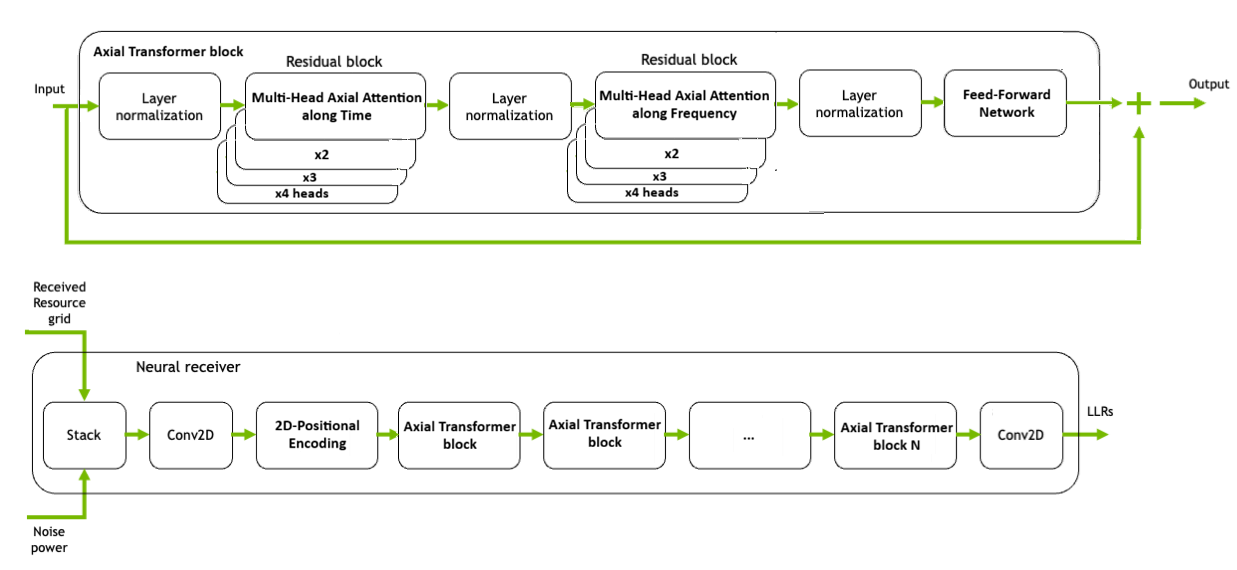

In [9]:
class LMMSEFeatureExtractor(nn.Module):
    """
    Computes analytical LMMSE (MMSE) soft-equalized QAM symbols
    from SIMO received grid y, LS channel estimate h_ls, and noise variance N0.
    """
    def __init__(self):
        super().__init__()

    def forward(self, y: torch.Tensor, h_ls: torch.Tensor, no: torch.Tensor) -> torch.Tensor:
        # y: (B, Rx, T, F) complex
        # h_ls: (B, Rx, T, F) complex
        # no: (B, 1, 1, 1) real noise variance
        num = torch.sum(torch.conj(h_ls) * y, dim=1, keepdim=True)  # (B, 1, T, F)
        denom = torch.sum(torch.abs(h_ls)**2, dim=1, keepdim=True) + no  # (B, 1, T, F)
        x_lmmse = num / (denom + 1e-8)
        return x_lmmse  # (B, 1, T, F) complex


class PositionalEncoding2D(nn.Module):
    """
    Learned 2D positional embedding for Time-Frequency OFDM Grid (B, T, F, C).
    """
    def __init__(self, d_model: int, max_time: int = 14, max_freq: int = 128):
        super().__init__()
        self.time_embed = nn.Parameter(torch.randn(1, max_time, 1, d_model) * 0.02)
        self.freq_embed = nn.Parameter(torch.randn(1, 1, max_freq, d_model) * 0.02)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        time_dim = x.size(1)
        freq_dim = x.size(2)
        return x + self.time_embed[:, :time_dim, :, :] + self.freq_embed[:, :, :freq_dim, :]


class AxialAttentionBlock(nn.Module):
    """
    Factorized 2D Axial Self-Attention Block.
    Performs Frequency-axis attention followed by Time-axis attention.
    Drastically reduces computational complexity from O((T*F)^2) to O(T*F^2 + F*T^2).
    """
    def __init__(self, d_model: int, nhead: int = 4, dim_feedforward: int = None, dropout: float = 0.1):
        super().__init__()
        if dim_feedforward is None:
            dim_feedforward = d_model * 4

        # Frequency-Axis Self-Attention (Seq Len = F)
        self.freq_attn = nn.MultiheadAttention(d_model, nhead, dropout=dropout, batch_first=True)
        self.norm_freq = nn.LayerNorm(d_model)

        # Time-Axis Self-Attention (Seq Len = T)
        self.time_attn = nn.MultiheadAttention(d_model, nhead, dropout=dropout, batch_first=True)
        self.norm_time = nn.LayerNorm(d_model)

        # Feed-Forward Network (FFN)
        self.ffn = nn.Sequential(
            nn.Linear(d_model, dim_feedforward),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(dim_feedforward, d_model),
            nn.Dropout(dropout)
        )
        self.norm_ffn = nn.LayerNorm(d_model)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # Input x shape: (B, T, F, C)
        B, T, F_dim, C = x.shape

        # 1. Frequency-Domain Attention (across F for each T)
        x_freq = x.view(B * T, F_dim, C)
        attn_freq, _ = self.freq_attn(x_freq, x_freq, x_freq)
        x_freq = self.norm_freq(x_freq + attn_freq).view(B, T, F_dim, C)

        # 2. Time-Domain Attention (across T for each F)
        x_time = x_freq.permute(0, 2, 1, 3).reshape(B * F_dim, T, C)
        attn_time, _ = self.time_attn(x_time, x_time, x_time)
        x_time = attn_time.view(B, F_dim, T, C).permute(0, 2, 1, 3)
        x_time = self.norm_time(x_freq + x_time)

        # 3. Feed-Forward Network
        out = self.norm_ffn(x_time + self.ffn(x_time))
        return out


class NeuralReceiver_proposed(nn.Module):
    """
    Hybrid LMMSE + Axial Self-Attention Neural Receiver.
    """
    def __init__(
        self,
        num_conv_channels: int = 128,
        num_bits_per_symbol: int = 6,
        nhead: int = 4,
        num_layers: int = 6, #3
        max_time: int = 14,
        max_freq: int = 128
    ):
        super().__init__()
        self._num_bits_per_symbol = num_bits_per_symbol
        d_model = num_conv_channels

        # LMMSE Analytical Feature Generator
        self.lmmse_extractor = LMMSEFeatureExtractor()

        # Channel breakdown:
        # y (real/imag * 2 rx) = 4
        # h_ls (real/imag * 2 rx) = 4
        # x_lmmse (real/imag * 1 stream) = 2
        # noise N0 (1) = 1
        # Total Input Channels = 11
        num_input_channels = 11
        self.input_proj = nn.Linear(num_input_channels, d_model)

        self.pos_encoder_2d = PositionalEncoding2D(d_model, max_time=max_time, max_freq=max_freq)

        # Stack of Axial Attention Blocks
        self.axial_layers = nn.ModuleList([
            AxialAttentionBlock(d_model=d_model, nhead=nhead, dim_feedforward=d_model * 2)
            for _ in range(num_layers)
        ])

        self.output_proj = nn.Linear(d_model, num_bits_per_symbol)

    def forward(self, y: torch.Tensor, h_ls: torch.Tensor, no: torch.Tensor) -> torch.Tensor:
        # y, h_ls: (B, Rx, T, F) complex
        # no: (B, 1, 1, 1) real noise variance
        batch_size, rx_ant, time_dim, freq_dim = y.shape

        # 1. Compute LMMSE Equalized Soft Symbol Feature
        x_lmmse = self.lmmse_extractor(y, h_ls, no)  # (B, 1, T, F) complex

        # 2. Extract Real & Imaginary Features
        y_real, y_imag = y.real, y.imag
        h_ls_real, h_ls_imag = h_ls.real, h_ls.imag
        x_lmmse_real, x_lmmse_imag = x_lmmse.real, x_lmmse.imag

        # Expand Noise Variance to 4D Grid
        no_log = torch.log10(no.view(batch_size, 1, 1, 1)).expand(batch_size, 1, time_dim, freq_dim)

        # 3. Concatenate Features along Channel Dim (Dim 1)
        z = torch.cat([
            y_real[:, 0:1], y_real[:, 1:2],
            y_imag[:, 0:1], y_imag[:, 1:2],
            h_ls_real[:, 0:1], h_ls_real[:, 1:2],
            h_ls_imag[:, 0:1], h_ls_imag[:, 1:2],
            x_lmmse_real, x_lmmse_imag,  # Hybrid LMMSE feature
            no_log
        ], dim=1)  # Shape: (B, 11, T, F)

        # 4. Project to Feature Dimension d_model
        z = z.permute(0, 2, 3, 1)  # (B, T, F, 11)
        z = self.input_proj(z)     # (B, T, F, d_model)
        z = self.pos_encoder_2d(z)  # Apply 2D Positional Encoding

        # 5. Process through Factorized Axial Attention Layers
        for layer in self.axial_layers:
            z = layer(z)

        # 6. Output Projection to LLRs
        z = self.output_proj(z)  # (B, T, F, num_bits_per_symbol)

        return z


## End-to-end System <a class="anchor" id="End-to-end-System"></a>

The following cell defines the end-to-end system.

Training is done on the bit-metric decoding (BMD) rate which is computed from the transmitted bits and LLRs:

\begin{equation}
R = 1 - \frac{1}{SNMK} \sum_{s = 0}^{S-1} \sum_{n = 0}^{N-1} \sum_{m = 0}^{M-1} \sum_{k = 0}^{K-1} \texttt{BCE} \left( B_{s,n,m,k}, \texttt{LLR}_{s,n,m,k} \right)
\end{equation}

where

* $S$ is the batch size
* $N$ the number of subcarriers
* $M$ the number of OFDM symbols
* $K$ the number of bits per symbol
* $B_{s,n,m,k}$ the $k^{th}$ coded bit transmitted on the resource element $(n,m)$ and for the $s^{th}$ batch example
* $\texttt{LLR}_{s,n,m,k}$ the LLR (logit) computed by the neural receiver corresponding to the $k^{th}$ coded bit transmitted on the resource element $(n,m)$ and for the $s^{th}$ batch example
* $\texttt{BCE} \left( \cdot, \cdot \right)$ the binary cross-entropy in log base 2

Because no outer code is required at training, the outer encoder and decoder are not used at training to reduce computational complexity.

The BMD rate is known to be an achievable information rate for BICM systems, which motivates its used as objective function [4].

In [11]:
## Transmitter
binary_source = BinarySource()
mapper = Mapper("qam", num_bits_per_symbol)
rg_mapper = ResourceGridMapper(resource_grid)

## Channel
cdl = CDL(cdl_model, delay_spread, carrier_frequency,
          ut_antenna, bs_array, "uplink", min_speed=min_speed, max_speed=max_speed)
channel = OFDMChannel(cdl, resource_grid, normalize_channel=True, return_channel=True)

## Receiver Components
ls_est = LSChannelEstimator(resource_grid, interpolation_type="nn")
rg_demapper = ResourceGridDemapper(resource_grid, stream_manager)

# Khởi tạo rõ ràng 2 kiến trúc mạng với tên biến độc lập
neural_receiver_cnn = NeuralReceiver_CNN(num_conv_channels, num_bits_per_symbol).to(device)
neural_receiver_axial = NeuralReceiver_proposed(num_conv_channels, num_bits_per_symbol).to(device)


The following cell performs one forward step through the end-to-end system:

In [12]:
batch_size = 64
ebno_db = torch.full((batch_size,), 5.0)
no = ebnodb2no(ebno_db, num_bits_per_symbol, coderate)

## Transmitter
# Generate codewords
c = binary_source([batch_size, 1, 1, n])
print("c shape: ", c.shape)
# Map bits to QAM symbols
x = mapper(c)
# Map the QAM symbols to a resource grid
x_rg = rg_mapper(x)

######################################
## Channel
no_ = expand_to_rank(no, x_rg.ndim)
y, _ = channel(x_rg, no_)
print("y shape: ", y.shape)

######################################
## Tiền xử lý chung
y_sq = y.squeeze(1)

######################################
## Receiver 1: CNN-ResNet
# Mạng CNN gốc sử dụng trực tiếp biến `no` ở dạng 1D[cite: 1]
llr_cnn = neural_receiver_cnn(y_sq, no)
llr_cnn = insert_dims(llr_cnn, 2, 1)
llr_cnn = rg_demapper(llr_cnn)
llr_cnn = llr_cnn.reshape(batch_size, 1, 1, n)
print("CNN LLRs shape: ", llr_cnn.shape)

######################################
## Receiver 2: Proposed Axial Attention
h_ls, err_var = ls_est(y, no)

# Force the MIMO channel tensor into the 4D signal shape[cite: 2]
h_ls_sq = h_ls.view(batch_size, y_sq.shape[1], y_sq.shape[2], -1)

# Correctly place LS Estimate onto full FFT grid using Sionna's effective_subcarrier_ind
h_ls_full = torch.zeros_like(y_sq)
h_ls_full[..., resource_grid.effective_subcarrier_ind] = h_ls_sq

# Format `no` to meet the NeuralReceiver's explicit (B, 1, 1, 1) demand[cite: 2]
no_formatted = no.view(batch_size, 1, 1, 1)

llr_proposed = neural_receiver_axial(y_sq, h_ls_full, no_formatted)
llr_proposed = insert_dims(llr_proposed, 2, 1)
llr_proposed = rg_demapper(llr_proposed)
llr_proposed = llr_proposed.reshape(batch_size, 1, 1, n)
print("Proposed LLRs shape: ", llr_proposed.shape)


c shape:  torch.Size([64, 1, 1, 8352])
y shape:  torch.Size([64, 1, 2, 14, 128])
CNN LLRs shape:  torch.Size([64, 1, 1, 8352])
Proposed LLRs shape:  torch.Size([64, 1, 1, 8352])


The BMD rate is computed from the LLRs and transmitted bits as follows:

In [13]:
bce_cnn = torch.nn.functional.binary_cross_entropy_with_logits(llr_cnn, c.float(), reduction='none')
rate_cnn = 1.0 - bce_cnn.mean() / math.log(2.)
print(f"CNN Rate: {rate_cnn:.2E} bit")
bce_proposed = torch.nn.functional.binary_cross_entropy_with_logits(llr_proposed, c.float(), reduction='none')
rate_proposed = 1.0 - bce_proposed.mean() / math.log(2.)
print(f"Proposed Rate: {rate_proposed:.2E} bit")

CNN Rate: -7.48E-02 bit
Proposed Rate: -6.73E-02 bit


The rate is very poor (negative values means 0 bit) as the neural receiver is not trained.

## End-to-end System as a Sionna Block

The following Sionna block implements the three considered end-to-end systems (perfect CSI baseline, LS estimation baseline, and neural receiver).

When instantiating the end-to-end model, the parameter ``system`` is used to specify the system to setup, and the parameter ``training`` is used to specified if the system is instantiated to be trained or to be evaluated. The ``training`` parameter is only relevant when the neural receiver is used.

At each call of this model:

* A batch of codewords is randomly sampled, modulated, and mapped to resource grids to form the channel inputs
* A batch of channel realizations is randomly sampled and applied to the channel inputs
* The receiver is executed on the post-DFT received samples to compute LLRs on the coded bits.
  Which receiver is executed (baseline with perfect CSI knowledge, baseline with LS estimation, or neural receiver) depends on the specified ``system`` parameter.
* If not training, the outer decoder is applied to reconstruct the information bits
* If training, the BMD rate is estimated over the batch from the LLRs and the transmitted bits


In [14]:
import random
import math
class E2ESystem(Block):
    def __init__(self, system, training=False, cdl_model=None):
        super().__init__()
        self._system = system
        self._training = training
        self._cdl_model = cdl_model.upper() if isinstance(cdl_model, str) else cdl_model
        self._resource_grid = resource_grid

        ## Transmitter
        self._binary_source = BinarySource()
        if not training:
            self._encoder = LDPC5GEncoder(k, n)
        self._mapper = Mapper("qam", num_bits_per_symbol)
        self._rg_mapper = ResourceGridMapper(resource_grid)

        ## Channel
        # Hỗ trợ toàn diện các mô hình kênh 3GPP CDL: 'A', 'B', 'C', 'D', 'E'
        if self._cdl_model is not None:
            # Khởi tạo đúng 100% kênh CDL được yêu cầu (chuẩn 3GPP TR 38.901)
            cdl = CDL(self._cdl_model, delay_spread, carrier_frequency,
                      ut_antenna, bs_array, "uplink", min_speed=min_speed, max_speed=max_speed)
            self._channel = OFDMChannel(cdl, resource_grid, normalize_channel=True, return_channel=True)
        else:
            # Khi cdl_model là None (mặc định lúc train đa kênh): Luân phiên ngẫu nhiên 3 kênh B, C, D
            cdl_b = CDL("B", delay_spread, carrier_frequency,
                        ut_antenna, bs_array, "uplink", min_speed=min_speed, max_speed=max_speed)
            cdl_c = CDL("C", delay_spread, carrier_frequency,
                        ut_antenna, bs_array, "uplink", min_speed=min_speed, max_speed=max_speed)
            cdl_d = CDL("D", delay_spread, carrier_frequency,
                        ut_antenna, bs_array, "uplink", min_speed=min_speed, max_speed=max_speed)
            self._channel_b = OFDMChannel(cdl_b, resource_grid, normalize_channel=True, return_channel=True)
            self._channel_c = OFDMChannel(cdl_c, resource_grid, normalize_channel=True, return_channel=True)
            self._channel_d = OFDMChannel(cdl_d, resource_grid, normalize_channel=True, return_channel=True)

        ## Receiver Routing
        if self._system == 'baseline-perfect-csi':
            self._removed_null_subc = RemoveNulledSubcarriers(resource_grid)
            self._lmmse_equ = LMMSEEqualizer(resource_grid, stream_manager)
            self._demapper = Demapper("app", "qam", num_bits_per_symbol)

        elif self._system == 'baseline-ls-estimation':
            self._ls_est = LSChannelEstimator(resource_grid, interpolation_type="nn")
            self._lmmse_equ = LMMSEEqualizer(resource_grid, stream_manager)
            self._demapper = Demapper("app", "qam", num_bits_per_symbol)

        elif self._system == "neural-receiver-cnn":
            self._neural_receiver = NeuralReceiver_CNN(num_conv_channels, num_bits_per_symbol).to(device)
            self._rg_demapper = ResourceGridDemapper(resource_grid, stream_manager)

        elif self._system == "neural-receiver-axial":
            self._ls_est = LSChannelEstimator(resource_grid, interpolation_type="nn")
            self._neural_receiver = NeuralReceiver_proposed(num_conv_channels, num_bits_per_symbol).to(device)
            self._rg_demapper = ResourceGridDemapper(resource_grid, stream_manager)

        if not training:
            self._decoder = LDPC5GDecoder(self._encoder, hard_out=True)

    def forward(self, batch_size, ebno_db):
        ebno_db = ebno_db.expand(batch_size)

        ## Transmitter
        no = ebnodb2no(ebno_db, num_bits_per_symbol, coderate)
        if self._training:
            c = self._binary_source([batch_size, 1, 1, n])
        else:
            b = self._binary_source([batch_size, 1, 1, k])
            c = self._encoder(b)

        x = self._mapper(c)
        x_rg = self._rg_mapper(x)

        ## Channel
        no_ = expand_to_rank(no, x_rg.ndim)
        if self._cdl_model is not None:
            # Sử dụng đúng 100% mô hình kênh CDL được yêu cầu
            y, h = self._channel(x_rg, no_)
        else:
            # Luân phiên ngẫu nhiên 3 kênh B, C, D (1/3 xác suất mỗi kênh khi train)
            rand_val = random.random()
            if rand_val < (1.0 / 3.0):
                y, h = self._channel_b(x_rg, no_)
            elif rand_val < (2.0 / 3.0):
                y, h = self._channel_c(x_rg, no_)
            else:
                y, h = self._channel_d(x_rg, no_)

        ## Receiver
        if self._system == 'baseline-perfect-csi':
            h_hat = self._removed_null_subc(h)
            x_hat, no_eff = self._lmmse_equ(y, h_hat, 0.0, no)
            no_eff_ = expand_to_rank(no_eff, x_hat.ndim)
            llr = self._demapper(x_hat, no_eff_)

        elif self._system == 'baseline-ls-estimation':
            h_hat, err_var = self._ls_est(y, no)
            x_hat, no_eff = self._lmmse_equ(y, h_hat, err_var, no)
            no_eff_ = expand_to_rank(no_eff, x_hat.ndim)
            llr = self._demapper(x_hat, no_eff_)

        elif self._system == "neural-receiver-cnn":
            y_sq = y.squeeze(1)
            llr = self._neural_receiver(y_sq, no)
            llr = insert_dims(llr, 2, 1)
            llr = self._rg_demapper(llr)
            llr = llr.reshape(batch_size, 1, 1, n)

        elif self._system == "neural-receiver-axial":
            h_ls, err_var = self._ls_est(y, no)
            y_sq = y.squeeze(1)
            h_ls = h_ls.view(batch_size, y_sq.shape[1], y_sq.shape[2], -1)
            h_ls_full = torch.zeros_like(y_sq)
            h_ls_full[..., self._resource_grid.effective_subcarrier_ind] = h_ls
            no_formatted = no.view(batch_size, 1, 1, 1)

            llr = self._neural_receiver(y_sq, h_ls_full, no_formatted)
            llr = insert_dims(llr, 2, 1)
            llr = self._rg_demapper(llr)
            llr = llr.reshape(batch_size, 1, 1, n)

        if self._training:
            bce = torch.nn.functional.binary_cross_entropy_with_logits(llr, c.float(), reduction='none')
            return 1.0 - bce.mean() / math.log(2.)
        else:
            b_hat = self._decoder(llr)
            return b, b_hat


## Evaluation of the Baselines <a class="anchor" id="Evaluation-of-the-Baselines"></a>

We evaluate the BERs achieved by the baselines in the next cell.

**Note:** Evaluation of the two systems can take a while. Therefore, we provide pre-computed results at the end of this notebook.

In [15]:
# Range of SNRs over which the systems are evaluated
ebno_dbs = np.arange(ebno_db_min, # Min SNR for evaluation
                     ebno_db_max, # Max SNR for evaluation
                     0.5) # Step

## Training the Neural Receiver <a class="anchor" id="Training-the-Neural-Receiver"></a>

In [16]:
import torch
import numpy as np
import time
import torch.nn.functional as F

# Trả lại F.relu cho môi trường
globals()['F'] = F

def profile_neural_receiver(model_class, model_name, dummy_inputs, device):
    device_str = str(device).lower()
    print(f"✅ Đang đánh giá kiến trúc: **{model_name}** (Chạy trên: {device_str.upper()})")

    # Khởi tạo một bản sao mới tinh (Uncompiled) để thop đếm FLOPs không bị lỗi
    clean_model = model_class(
        num_conv_channels=num_conv_channels,
        num_bits_per_symbol=num_bits_per_symbol
    ).to(device)
    clean_model.eval()

    # ==============================================================================
    # 1. ĐO ĐỘ PHỨC TẠP KHÔNG GIAN (SPACE COMPLEXITY)
    # ==============================================================================
    total_params = sum(p.numel() for p in clean_model.parameters())
    trainable_params = sum(p.numel() for p in clean_model.parameters() if p.requires_grad)

    size_fp32_mb = (total_params * 4) / (1024 ** 2)
    size_fp16_mb = (total_params * 2) / (1024 ** 2)

    print("\n" + "="*60)
    print("💾 1. SPACE COMPLEXITY (PARAMETERS & MEMORY)")
    print("-" * 60)
    print(f"   - Total Parameters:         {total_params:,}")
    print(f"   - Trainable Parameters:     {trainable_params:,}")
    print(f"   - Model Weight Size (FP32): {size_fp32_mb:.2f} MB")
    print(f"   - Model Weight Size (FP16): {size_fp16_mb:.2f} MB")

    # ==============================================================================
    # 2. ĐO ĐỘ PHỨC TẠP TÍNH TOÁN (COMPUTATIONAL COMPLEXITY - FLOPs)
    # ==============================================================================
    print("\n" + "="*60)
    print("🧮 2. COMPUTATIONAL COMPLEXITY (FLOPs)")
    print("-" * 60)
    try:
        from thop import profile
        # Đo FLOPs trên bản sao sạch để tránh lỗi mất Hooks do torch.compile
        macs, _ = profile(clean_model, inputs=dummy_inputs, verbose=False)
        flops = macs * 2
        print(f"   - Total FLOPs:              {flops / 1e9:.4f} GFLOPs / Khung OFDM")
    except Exception as e:
        print(f"   - [Bỏ qua] Lỗi đo FLOPs: {e}")

    # ==============================================================================
    # 3. ĐO ĐỘ TRỄ SUY LUẬN (TIME COMPLEXITY - LATENCY)
    # ==============================================================================
    print("\n" + "="*60)
    print("⏱️ 3. TIME COMPLEXITY (INFERENCE LATENCY)")
    print("-" * 60)

    num_trials = 300
    latencies = []

    with torch.no_grad():
        # Warm-up
        for _ in range(50):
            _ = clean_model(*dummy_inputs)

        if 'cuda' in device_str:
            start_event = torch.cuda.Event(enable_timing=True)
            end_event = torch.cuda.Event(enable_timing=True)
            for _ in range(num_trials):
                start_event.record()
                _ = clean_model(*dummy_inputs)
                end_event.record()
                torch.cuda.synchronize()
                latencies.append(start_event.elapsed_time(end_event))
            hw_name = torch.cuda.get_device_name() # Lấy thẳng tên thiết bị mặc định
        else:
            for _ in range(num_trials):
                start_time = time.perf_counter()
                _ = clean_model(*dummy_inputs)
                end_time = time.perf_counter()
                latencies.append((end_time - start_time) * 1000)
            hw_name = "CPU"

    mean_latency = np.mean(latencies)
    std_latency = np.std(latencies)

    print(f"   - Hardware:                 {hw_name}")
    print(f"   - Average Latency:          {mean_latency:.3f} ms ± {std_latency:.3f} ms")
    print(f"   - Est. Throughput:          {1000 / mean_latency:.0f} Khung/giây (Batch=1)")
    print("="*60 + "\n\n")

# ==============================================================================
# CHẠY ĐÁNH GIÁ CHO CẢ HAI MÔ HÌNH
# ==============================================================================
b_dim, rx_dim, t_dim, f_dim = 1, 2, 14, 128
y_dummy = torch.randn(b_dim, rx_dim, t_dim, f_dim, dtype=torch.complex64, device=device)
h_ls_dummy = torch.randn(b_dim, rx_dim, t_dim, f_dim, dtype=torch.complex64, device=device)

# 1. Chạy đánh giá cho CNN-ResNet
no_dummy_cnn = torch.tensor([0.1], device=device)
profile_neural_receiver(
    model_class=NeuralReceiver_CNN,
    model_name="Baseline: CNN-ResNet",
    dummy_inputs=(y_dummy, no_dummy_cnn),
    device=device
)

# 2. Chạy đánh giá cho Proposed Axial Attention
no_dummy_proposed = torch.tensor([0.1], device=device).view(b_dim, 1, 1, 1)
profile_neural_receiver(
    model_class=NeuralReceiver_proposed,
    model_name="Proposed: Hybrid LMMSE + Axial Attention",
    dummy_inputs=(y_dummy, h_ls_dummy, no_dummy_proposed),
    device=device
)

✅ Đang đánh giá kiến trúc: **Baseline: CNN-ResNet** (Chạy trên: CUDA:0)

💾 1. SPACE COMPLEXITY (PARAMETERS & MEMORY)
------------------------------------------------------------
   - Total Parameters:         13,352,198
   - Trainable Parameters:     13,352,198
   - Model Weight Size (FP32): 50.93 MB
   - Model Weight Size (FP16): 25.47 MB

🧮 2. COMPUTATIONAL COMPLEXITY (FLOPs)
------------------------------------------------------------
   - Total FLOPs:              11.7124 GFLOPs / Khung OFDM

⏱️ 3. TIME COMPLEXITY (INFERENCE LATENCY)
------------------------------------------------------------
   - Hardware:                 Tesla T4
   - Average Latency:          9.630 ms ± 0.040 ms
   - Est. Throughput:          104 Khung/giây (Batch=1)


✅ Đang đánh giá kiến trúc: **Proposed: Hybrid LMMSE + Axial Attention** (Chạy trên: CUDA:0)

💾 1. SPACE COMPLEXITY (PARAMETERS & MEMORY)
------------------------------------------------------------
   - Total Parameters:         1,213,318
   - Tr

In the next cell, one forward pass is performed within a *gradient tape*, which enables the computation of gradient and therefore the optimization of the neural network through stochastic gradient descent (SGD).

**Note:** For an introduction to the implementation of differentiable communication systems and their optimization through SGD and backpropagation with Sionna, please refer to [the Part 2 of the Sionna tutorial for Beginners](https://nvlabs.github.io/sionna/phy/tutorials/notebooks/Sionna_tutorial_part2.html).

# Training consists in looping over SGD steps. The next cell implements a training loop.

At each iteration:
- A batch of SNRs $E_b/N_0$ is sampled
- A forward pass through the end-to-end system is performed within a gradient tape
- The gradients are computed using the gradient tape, and applied using the Adam optimizer
- The achieved BMD rate is periodically shown

After training, the weights of the models are saved in a file

**Note:** Training can take a while. Therefore, [we have made pre-trained weights available](https://drive.google.com/file/d/1wjBB3U8Cp4a6VMZSrLBYJl6aG5sPoG_I/view?usp=sharing). Do not execute the next cell if you don't want to train the model from scratch.

In [17]:
# Training setup
import os, re, shutil, time
from google.colab import drive, files

training = True
continued = False
accumulation_steps = 8
timer = 5.0

# Drive mount
if not os.path.exists('/content/drive/MyDrive'):
    try:
        drive.mount('/content/drive')
    except Exception:
        pass

# File paths
drive_dir = '/content/drive/MyDrive/Thesis_Checkpoints'
os.makedirs(drive_dir, exist_ok=True)

# Helper: regex iteration
def extract_iteration_from_filename(filename):
    match = re.search(r'iter_(\d+)', filename, re.IGNORECASE)
    return int(match.group(1)) if match else 0

# Helper: format time (HH:MM:SS)
def format_time(seconds):
    h = int(seconds // 3600)
    m = int((seconds % 3600) // 60)
    s = int(seconds % 60)
    return f"{h:02d}:{m:02d}:{s:02d}"

# Speed validation
if training:
    if min_speed == max_speed:
        ans = input(f"Train with constant speed {min_speed} m/s? (y/n): ")
        if ans.strip().lower() not in ['y', 'yes']:
            raise ValueError(f"Aborted: min_speed == max_speed ({min_speed} m/s).")
else:
    max_speed = min_speed
    if min_speed == 0.0:
        ans = input("Eval with static channel min_speed = 0.0 m/s? (y/n): ")
        if ans.strip().lower() not in ['y', 'yes']:
            raise ValueError("Aborted: min_speed is 0.0 m/s.")

if training:
    # Model selection
    choice = input("Select model to train (1: CNN-ResNet, 2: Proposed Axial Attention): ").strip()
    if choice == '1':
        receiver_type = 'neural-receiver-cnn'
        current_weights_name = f"{model_weights_path}_CNN"
    else:
        receiver_type = 'neural-receiver-axial'
        current_weights_name = model_weights_path

    final_path = f'/content/{current_weights_name}'
    checkpoint_path = f'/content/{current_weights_name}.pt'
    drive_final_path = os.path.join(drive_dir, current_weights_name)
    drive_checkpoint_path = os.path.join(drive_dir, f"{current_weights_name}.pt")

    # Model and optimizer
    model = torch.compile(E2ESystem(receiver_type, training=True))
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)
    start_iter = 0
    prev_elapsed_time = 0.0

    # Resume: local upload
    if continued:
        uploaded = files.upload()
        if uploaded:
            uploaded_filename = list(uploaded.keys())[0]
            extracted_iter = extract_iteration_from_filename(uploaded_filename)
            if os.path.abspath(uploaded_filename) != os.path.abspath(checkpoint_path):
                shutil.move(uploaded_filename, checkpoint_path)
            checkpoint = torch.load(checkpoint_path)
            if isinstance(checkpoint, dict) and 'model_state_dict' in checkpoint:
                model._orig_mod._neural_receiver.load_state_dict(checkpoint['model_state_dict'])
                if 'optimizer_state_dict' in checkpoint:
                    optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
                start_iter = checkpoint.get('iteration', extracted_iter)
                prev_elapsed_time = checkpoint.get('total_elapsed_seconds', 0.0)
            else:
                model._orig_mod._neural_receiver.load_state_dict(checkpoint)
                optimizer.zero_grad()
                start_iter = extracted_iter if extracted_iter > 0 else 0
        else:
            optimizer.zero_grad()
    else:
        # Resume: Drive auto-restore
        if not os.path.exists(checkpoint_path) and os.path.exists(drive_checkpoint_path):
            try:
                shutil.copy(drive_checkpoint_path, checkpoint_path)
            except Exception:
                pass

        # Resume: load checkpoint
        if os.path.exists(checkpoint_path):
            checkpoint = torch.load(checkpoint_path)
            if isinstance(checkpoint, dict) and 'model_state_dict' in checkpoint:
                model._orig_mod._neural_receiver.load_state_dict(checkpoint['model_state_dict'])
                if 'optimizer_state_dict' in checkpoint:
                    optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
                start_iter = checkpoint.get('iteration', 0)
                prev_elapsed_time = checkpoint.get('total_elapsed_seconds', 0.0)
            else:
                model._orig_mod._neural_receiver.load_state_dict(checkpoint)
                optimizer.zero_grad()
                start_iter = extract_iteration_from_filename(checkpoint_path)
        else:
            optimizer.zero_grad()

    # Training loop
    start_session_time = time.time()
    try:
        for i in range(start_iter, num_training_iterations):
            ebno_db = torch.empty(1, device=device).uniform_(ebno_db_min, ebno_db_max)
            rate = model(training_batch_size, ebno_db)

            loss = -rate / accumulation_steps
            loss.backward()

            if (i + 1) % accumulation_steps == 0:
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                optimizer.step()
                optimizer.zero_grad()

            elapsed_session = time.time() - start_session_time

            # Display progress and update sidebar checkpoint
            if i % 100 == 0:
                print(f"Iteration {i}/{num_training_iterations}  Rate: {rate.item():.4f} bit | Elapsed: {format_time(elapsed_session)}")
                checkpoint_data = {
                    'iteration': i,
                    'model_state_dict': model._orig_mod._neural_receiver.state_dict(),
                    'optimizer_state_dict': optimizer.state_dict(),
                    'session_seconds': elapsed_session,
                    'total_elapsed_seconds': prev_elapsed_time + elapsed_session
                }
                torch.save(checkpoint_data, checkpoint_path)

            # Timer interrupt
            if elapsed_session >= (timer * 3600):
                raise KeyboardInterrupt

        # Completed: save final model (no extension)
        torch.save(model._orig_mod._neural_receiver.state_dict(), final_path)
        if os.path.exists('/content/drive/MyDrive'):
            try:
                shutil.copy(final_path, drive_final_path)
            except Exception:
                pass

        if os.path.exists(checkpoint_path):
            os.remove(checkpoint_path)
        if os.path.exists(drive_checkpoint_path):
            try:
                os.remove(drive_checkpoint_path)
            except Exception:
                pass

        files.download(final_path)

    except KeyboardInterrupt:
        # Interrupted: save checkpoint (.pt)
        elapsed_session = time.time() - start_session_time
        checkpoint_data = {
            'iteration': i + 1,
            'model_state_dict': model._orig_mod._neural_receiver.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'session_seconds': elapsed_session,
            'total_elapsed_seconds': prev_elapsed_time + elapsed_session
        }
        torch.save(checkpoint_data, checkpoint_path)
        if os.path.exists('/content/drive/MyDrive'):
            try:
                shutil.copy(checkpoint_path, drive_checkpoint_path)
            except Exception:
                pass
        files.download(checkpoint_path)

else:
    pass

📥 [Đánh giá] Vui lòng tải lên file weight (KHÔNG ĐUÔI) cho mô hình CNN:


Saving neural_receiver_results_C_128_0-97_64-QAM_9-10_CNN to neural_receiver_results_C_128_0-97_64-QAM_9-10_CNN
✅ Đã tải và lưu trữ weight CNN thành công.

📥 [Đánh giá] Vui lòng tải lên file weight (KHÔNG ĐUÔI) cho mô hình PROPOSED:


Saving neural_receiver_results_C_128_0-50_64-QAM_9-10 to neural_receiver_results_C_128_0-50_64-QAM_9-10
✅ Đã tải và lưu trữ weight Proposed thành công.

🚀 Đã hoàn tất bước nạp weights. Bạn có thể chạy Cell Evaluation ở bên dưới.


## Evaluation of the Neural Receiver <a class="anchor" id="Evaluation-of-the-Neural-Receiver"></a>

The next cell evaluates the neural receiver.

**Note:** Evaluation of the system can take a while and requires having the trained weights of the neural receiver.

In [ ]:
# Evaluation parameters
cdl_model = "C"
min_speed = 40.0
max_speed = min_speed
if min_speed == 0.0:
    ans = input("Eval with static channel min_speed = 0.0 m/s? (y/n): ")
    if ans.strip().lower() not in ['y', 'yes']:
        raise ValueError("Aborted: min_speed is 0.0 m/s.")

ebno_dbs = np.arange(0, 21, 1.0)
BLER = {}
channel_name = cdl_model.upper()

# Baseline - Perfect CSI
model = E2ESystem('baseline-perfect-csi', cdl_model=cdl_model)
_, bler = sim_ber(model, ebno_dbs, batch_size=128, num_target_block_errors=100, max_mc_iter=1000, target_bler=1e-4, compile_mode="reduce-overhead")
BLER['baseline-perfect-csi'] = bler.cpu().numpy()
del model
if torch.cuda.is_available():
    torch.cuda.empty_cache()

# Baseline - LS Estimation
model = E2ESystem('baseline-ls-estimation', cdl_model=cdl_model)
_, bler = sim_ber(model, ebno_dbs, batch_size=128, num_target_block_errors=100, max_mc_iter=1000, target_bler=1e-4, compile_mode="reduce-overhead")
BLER['baseline-ls-estimation'] = bler.cpu().numpy()
del model
if torch.cuda.is_available():
    torch.cuda.empty_cache()

EbNo [dB] |        BER |       BLER |  bit errors |    num bits | block errors |  num blocks | runtime [s] |    status
---------------------------------------------------------------------------------------------------------------------------------------
      0.0 | 1.7955e-01 | 1.0000e+00 |      172735 |      962048 |          128 |         128 |         0.1 |reached target block errors
      0.5 | 1.7046e-01 | 1.0000e+00 |      163992 |      962048 |          128 |         128 |         0.1 |reached target block errors
      1.0 | 1.6225e-01 | 1.0000e+00 |      156095 |      962048 |          128 |         128 |         0.1 |reached target block errors
      1.5 | 1.5455e-01 | 1.0000e+00 |      148685 |      962048 |          128 |         128 |         0.1 |reached target block errors
      2.0 | 1.4542e-01 | 1.0000e+00 |      139903 |      962048 |          128 |         128 |         0.0 |reached target block errors
      2.5 | 1.3751e-01 | 1.0000e+00 |      132296 |      962048 |

In [ ]:
# Neural Receiver - CNN (DeepRx Baseline)
model = E2ESystem('neural-receiver-cnn', cdl_model=cdl_model)
model(1, torch.tensor(10.0))

cnn_weights = f"/content/{model_weights_path}_CNN"
drive_cnn_weights = os.path.join(drive_dir, f"{model_weights_path}_CNN")
if os.path.exists('/content/drive/MyDrive'):
    if os.path.exists(drive_cnn_weights) and not os.path.exists(cnn_weights):
        shutil.copy(drive_cnn_weights, cnn_weights)
    elif os.path.exists(f"{drive_cnn_weights}.pt") and not os.path.exists(f"{cnn_weights}.pt"):
        shutil.copy(f"{drive_cnn_weights}.pt", f"{cnn_weights}.pt")

load_path = cnn_weights if os.path.exists(cnn_weights) else f"{cnn_weights}.pt"
ckpt = torch.load(load_path, weights_only=True)
state = ckpt['model_state_dict'] if isinstance(ckpt, dict) and 'model_state_dict' in ckpt else ckpt
model._neural_receiver.load_state_dict(state)
model.eval()

_, bler = sim_ber(model, ebno_dbs, batch_size=128, num_target_block_errors=100, max_mc_iter=1000, target_bler=1e-4)
BLER['neural-receiver-cnn'] = bler.cpu().numpy()
del model
if torch.cuda.is_available():
    torch.cuda.empty_cache()

In [ ]:
# Neural Receiver - Proposed Axial Attention
model = E2ESystem('neural-receiver-axial', cdl_model=cdl_model)
model(1, torch.tensor(10.0))

axial_weights = f"/content/{model_weights_path}"
drive_axial_weights = os.path.join(drive_dir, model_weights_path)
if os.path.exists('/content/drive/MyDrive'):
    if os.path.exists(drive_axial_weights) and not os.path.exists(axial_weights):
        shutil.copy(drive_axial_weights, axial_weights)
    elif os.path.exists(f"{drive_axial_weights}.pt") and not os.path.exists(f"{axial_weights}.pt"):
        shutil.copy(f"{drive_axial_weights}.pt", f"{axial_weights}.pt")

load_path = axial_weights if os.path.exists(axial_weights) else f"{axial_weights}.pt"
ckpt = torch.load(load_path, weights_only=True)
state = ckpt['model_state_dict'] if isinstance(ckpt, dict) and 'model_state_dict' in ckpt else ckpt
model._neural_receiver.load_state_dict(state)
model.eval()

_, bler = sim_ber(model, ebno_dbs, batch_size=128, num_target_block_errors=100, max_mc_iter=1000, target_bler=1e-4)
BLER['neural-receiver-axial'] = bler.cpu().numpy()
del model
if torch.cuda.is_available():
    torch.cuda.empty_cache()

# Save evaluation profile (.npy) to local and Drive
eval_file = f"{results_filename}_CDL_{channel_name}_{min_speed:.0f}ms.npy"
np.save(eval_file, BLER)
if os.path.exists(drive_dir):
    try:
        shutil.copy(eval_file, os.path.join(drive_dir, eval_file))
    except Exception:
        pass

## Pre-computed Results <a class="anchor" id="Pre-computed-Results"></a>

Finally, we plot the BLERs

In [ ]:
# Plot BLER curves
plt.figure(figsize=(10,6))
channel_name = cdl_model.upper()

plt.semilogy(ebno_dbs, BLER['baseline-perfect-csi'], 'o-', c='C0', label='Baseline - Perfect CSI')
plt.semilogy(ebno_dbs, BLER['baseline-ls-estimation'], 'x--', c='C1', label='Baseline - LS Estimation')
plt.semilogy(ebno_dbs, BLER['neural-receiver-cnn'], 's-.', c='C2', label='Neural Receiver (CNN DeepRx)')
plt.semilogy(ebno_dbs, BLER['neural-receiver-axial'], 'd:', c='C3', label='Neural Receiver (Proposed Axial Attention)')

plt.xlabel(r"$E_b/N_0$ (dB)", fontsize=12)
plt.ylabel("Block Error Rate (BLER)", fontsize=12)
plt.title(f"BLER Performance Comparison over CDL-{channel_name} Channel (Speed = {min_speed} m/s)", fontsize=13)
plt.grid(which="both", linestyle="--", alpha=0.6)
plt.ylim((1e-4, 1.0))
plt.xlim((ebno_dbs[0], ebno_dbs[-1]))
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

## References <a class="anchor" id="References"></a>

[1] M. Honkala, D. Korpi and J. M. J. Huttunen, "DeepRx: Fully Convolutional Deep Learning Receiver," in IEEE Transactions on Wireless Communications, vol. 20, no. 6, pp. 3925-3940, June 2021, doi: 10.1109/TWC.2021.3054520.

[2] F. Ait Aoudia and J. Hoydis, "End-to-end Learning for OFDM: From Neural Receivers to Pilotless Communication," in IEEE Transactions on Wireless Communications, doi: 10.1109/TWC.2021.3101364.

[3] Kaiming He, Xiangyu Zhang, Shaoqing Ren, Jian Sun, "Deep Residual Learning for Image Recognition", Proceedings of the IEEE Conference on Computer Vision and Pattern Recognition (CVPR), 2016, pp. 770-778

[4] G. Böcherer, "Achievable Rates for Probabilistic Shaping", arXiv:1707.01134, 2017.